# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 2: Mendeley — Dataset of Vector Mosquito Images

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** CNN — Identificación de mosquitos  
**Dataset:** *Dataset of Vector Mosquito Images*, versión 4 (imágenes originales)  
**Fuente:** [Mendeley Data](https://data.mendeley.com/datasets/88s6fvgg2p/4) · DOI: [10.17632/88s6fvgg2p.4](https://doi.org/10.17632/88s6fvgg2p.4)

### Objetivo
Explorar la estructura, distribución de especies, dimensiones, formatos, características visuales y calidad de las imágenes originales para identificar problemas que deban considerarse antes del entrenamiento de una CNN.



## 1. Importación de librerías

Se importan las herramientas necesarias para explorar archivos, construir tablas, visualizar imágenes y calcular métricas de calidad y duplicación.

In [28]:
from pathlib import Path
from collections import Counter
import hashlib
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from IPython.display import display

## 2. Ubicación y estructura del dataset

Se localiza la carpeta de Mendeley dentro de `data/raw/mosquitos/` y se observan sus primeros niveles. El análisis está preparado para carpetas internas con nombres de especies.

In [29]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\Mendeley-aegypti_Culex_ Anopheles")

for carpeta in ruta.iterdir():
    print(carpeta.name)

Aedes Aegypti
Anopheles Stephensi
Culex Quinquefasciatus


## 3. Inventario de imágenes y etiquetas

Se enumeran las imágenes originales sin modificarlas y se intenta asignar una etiqueta según los nombres de carpetas y archivos. Es importante comprobar que las etiquetas inferidas coincidan con la organización real del dataset.

In [30]:
# Extensiones de imagen que vamos a analizar
extensiones = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}


def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore")
    return texto.decode("ascii").lower().replace("_", " ").replace("-", " ")


def identificar_especie(archivo):
    descripcion = normalizar(str(archivo.relative_to(ruta)))
    if "albopictus" in descripcion:
        return "Aedes albopictus"
    if "aegypti" in descripcion or "aedes" in descripcion:
        return "Aedes aegypti"
    if "anopheles" in descripcion or "stephensi" in descripcion:
        return "Anopheles stephensi"
    if "culex" in descripcion or "quinquefasciatus" in descripcion:
        return "Culex quinquefasciatus"
    return "Sin identificar"


archivos_imagen = sorted(
    p for p in ruta.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensiones
    and "augmented" not in normalizar(str(p.relative_to(ruta)))
)

if not archivos_imagen:
    raise FileNotFoundError(
        "No se encontraron imágenes extraídas. Descomprimí 'Mosquito Images Original.zip' "
        "dentro de la carpeta de Mendeley."
    )

inventario = pd.DataFrame([
    {
        "Ruta": str(archivo),
        "Archivo": archivo.name,
        "Carpeta padre": archivo.parent.name,
        "Clase": identificar_especie(archivo),
        "Extensión": archivo.suffix.lower(),
        "Tamaño (KB)": archivo.stat().st_size / 1024,
    }
    for archivo in archivos_imagen
])

print("Total de archivos de imagen:", len(inventario))
display(inventario[["Archivo", "Carpeta padre", "Clase", "Extensión", "Tamaño (KB)"]].head(12))
print("Imágenes sin etiqueta reconocida:", (inventario["Clase"] == "Sin identificar").sum())

Total de archivos de imagen: 44


,Archivo,Carpeta padre,Clase,Extensión,Tamaño (KB)
0,Aedes_aegypti_1.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2129.083008
1,Aedes_aegypti_10.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2093.684570
2,Aedes_aegypti_11.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2247.817383
3,Aedes_aegypti_12.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2209.982422
4,Aedes_aegypti_13.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2262.339844
5,Aedes_aegypti_14.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2597.300781
6,Aedes_aegypti_15.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2369.326172
7,Aedes_aegypti_2.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2297.327148
8,Aedes_aegypti_3.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2324.718750
9,Aedes_aegypti_4.jpg,Aedes Aegypti,Aedes aegypti,.jpg,2100.393555


Imágenes sin etiqueta reconocida: 0


## 4. Cantidad de imágenes por especie

Se contabilizan las imágenes disponibles por clase para conocer el tamaño del dataset y detectar especies con menor representación.

In [31]:
tabla_conteo = (
    inventario["Clase"]
    .value_counts()
    .rename_axis("Clase")
    .reset_index(name="Cantidad de imágenes")
)

display(tabla_conteo)
print("Total:", int(tabla_conteo["Cantidad de imágenes"].sum()))

,Clase,Cantidad de imágenes
0,Culex quinquefasciatus,20
1,Aedes aegypti,15
2,Anopheles stephensi,9


Total: 44


## 5. Distribución porcentual y gráfico de clases

Se calcula el porcentaje de imágenes por especie y se visualiza su frecuencia. Las diferencias entre clases pueden afectar el entrenamiento y la evaluación de la CNN.

,Clase,Cantidad de imágenes,Porcentaje (%)
0,Culex quinquefasciatus,20,45.45
1,Aedes aegypti,15,34.09
2,Anopheles stephensi,9,20.45


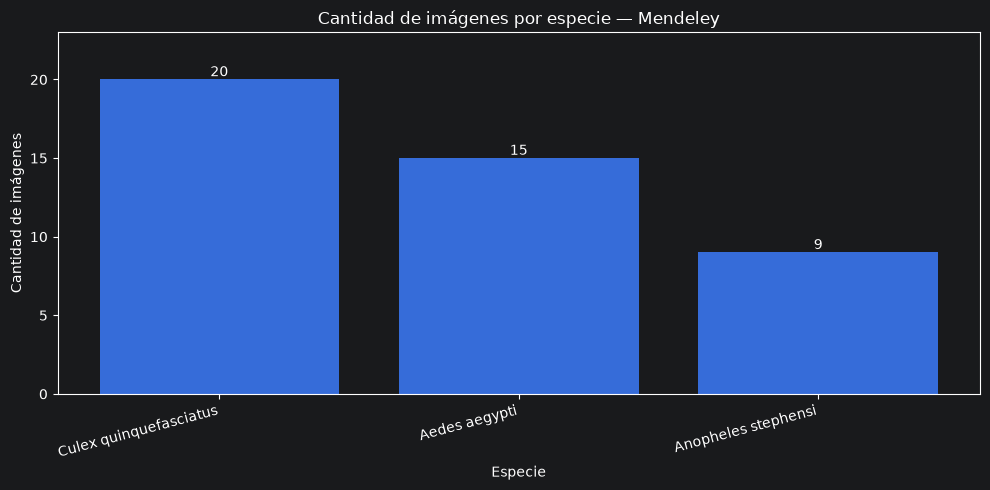

In [32]:
tabla_conteo["Porcentaje (%)"] = (
    100 * tabla_conteo["Cantidad de imágenes"]
    / tabla_conteo["Cantidad de imágenes"].sum()
).round(2)

display(tabla_conteo)

plt.figure(figsize=(10, 5))
barras = plt.bar(tabla_conteo["Clase"], tabla_conteo["Cantidad de imágenes"])
for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        str(int(barra.get_height())),
        ha="center", va="bottom"
    )
plt.title("Cantidad de imágenes por especie — Mendeley")
plt.xlabel("Especie")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, tabla_conteo["Cantidad de imágenes"].max() * 1.15)
plt.tight_layout()
plt.show()

## 6. Visualización de imágenes por clase

Se muestran ejemplos representativos para observar las especies, los fondos, la iluminación y posibles diferencias visuales entre grupos. La muestra es orientativa y no sustituye la revisión completa.

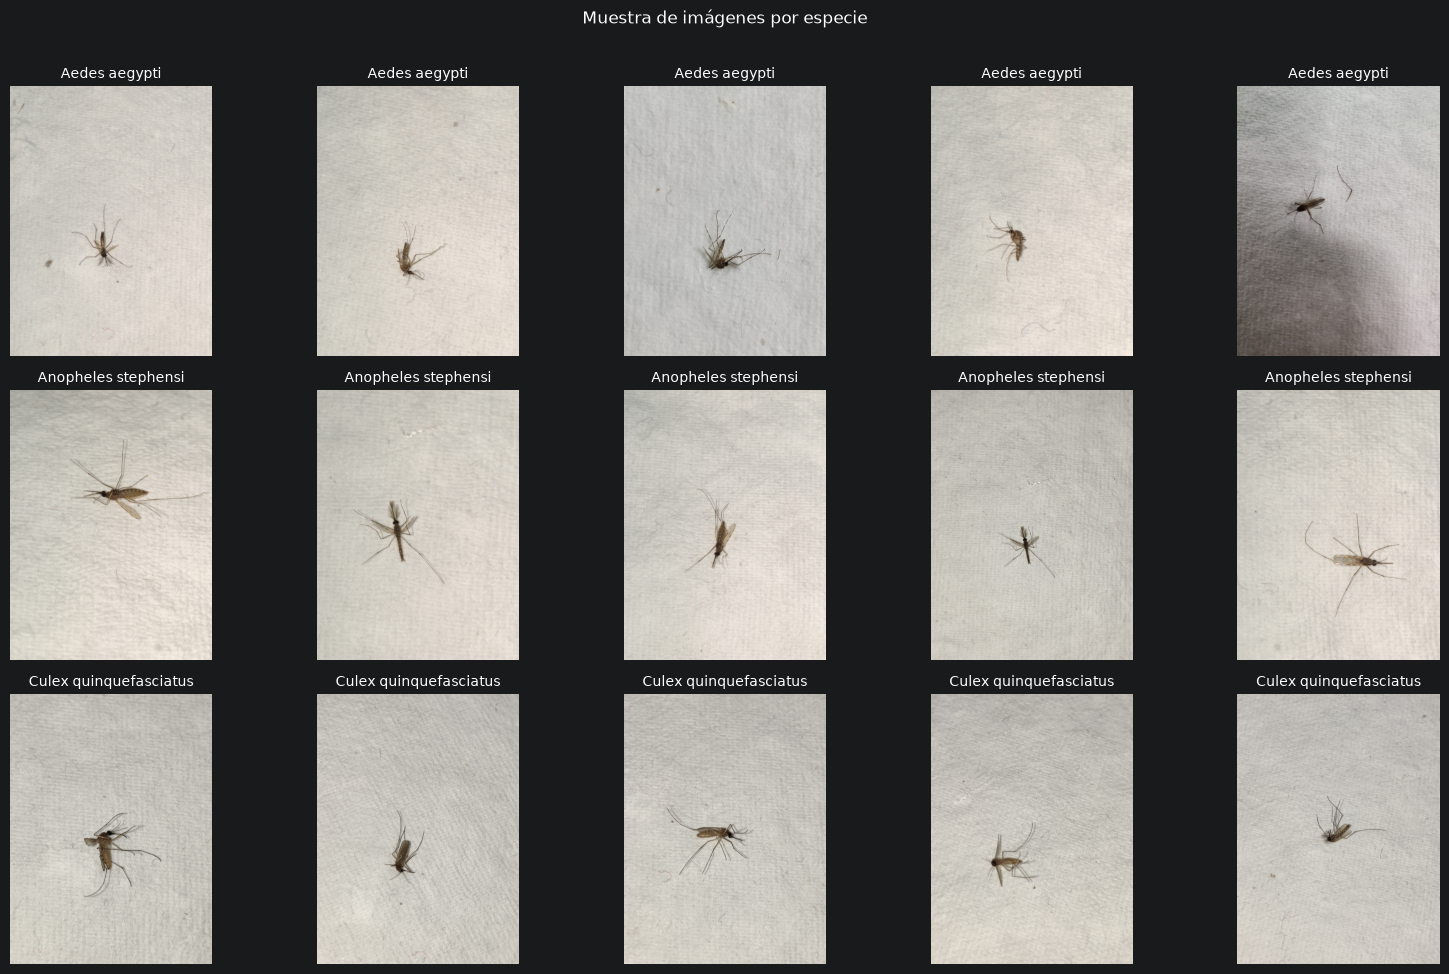

In [33]:
# Mostrar hasta cinco imágenes por clase (muestra reproducible)
clases = inventario["Clase"].unique().tolist()
columnas = 5
fig, ejes = plt.subplots(len(clases), columnas, figsize=(16, 3.2 * len(clases)), squeeze=False)

for fila, clase in enumerate(clases):
    muestra = inventario[inventario["Clase"] == clase].sample(
        n=min(columnas, (inventario["Clase"] == clase).sum()),
        random_state=42
    )
    for columna, (_, registro) in enumerate(muestra.iterrows()):
        with Image.open(registro["Ruta"]) as img:
            ejes[fila, columna].imshow(ImageOps.exif_transpose(img).convert("RGB"))
        ejes[fila, columna].set_title(clase, fontsize=10)
    for eje in ejes[fila]:
        eje.axis("off")

plt.suptitle("Muestra de imágenes por especie", y=1.01)
plt.tight_layout()
plt.show()

## 7. Integridad y metadatos de imágenes

Se intenta verificar y cargar cada imagen. Al mismo tiempo, se registran sus dimensiones, formato real y modo de color. Los archivos con error se reportan sin eliminarlos.

In [34]:
metadatos = []
for registro in inventario.itertuples(index=False):
    fila = {
        "Ruta": registro.Ruta,
        "Clase": registro.Clase,
        "Extensión": registro.Extensión,
        "Tamaño (KB)": getattr(registro, "_5", None),
        "Ancho": np.nan,
        "Alto": np.nan,
        "Formato real": None,
        "Modo de color": None,
        "Error": None,
    }
    try:
        with Image.open(registro.Ruta) as img:
            img.verify()
        with Image.open(registro.Ruta) as img:
            img.load()
            fila["Ancho"], fila["Alto"] = img.size
            fila["Formato real"] = img.format
            fila["Modo de color"] = img.mode
    except Exception as e:
        fila["Error"] = str(e)
    metadatos.append(fila)

df_meta = pd.DataFrame(metadatos)
# Conservar el tamaño desde el inventario mediante la ruta (sin depender de nombres de columnas de itertuples).
df_meta = df_meta.drop(columns=["Tamaño (KB)"]).merge(
    inventario[["Ruta", "Tamaño (KB)"]], on="Ruta", how="left"
)
df_validas = df_meta[df_meta["Error"].isna()].copy()
df_danadas = df_meta[df_meta["Error"].notna()].copy()

print("Archivos revisados:", len(df_meta))
print("Imágenes válidas:", len(df_validas))
print("Imágenes dañadas:", len(df_danadas))
display(df_danadas[["Ruta", "Clase", "Error"]].head(10))

Archivos revisados: 44
Imágenes válidas: 44
Imágenes dañadas: 0


,Ruta,Clase,Error


## 8. Análisis de dimensiones (ancho y alto)

Se calculan estadísticas descriptivas de las dimensiones. Esto permite determinar si las imágenes presentan tamaños homogéneos o requieren redimensionamiento.

Ancho                                                  \
                       count    mean     std     min     25%     50%     75%   
Clase                                                                          
Aedes aegypti           15.0  2859.2  371.57  1944.0  3000.0  3000.0  3000.0   
Anopheles stephensi      9.0  3000.0    0.00  3000.0  3000.0  3000.0  3000.0   
Culex quinquefasciatus  20.0  3000.0    0.00  3000.0  3000.0  3000.0  3000.0   

                                Alto                                           \
                           max count     mean     std     min     25%     50%   
Clase                                                                           
Aedes aegypti           3000.0  15.0  3812.27  495.43  2592.0  4000.0  4000.0   
Anopheles stephensi     3000.0   9.0  4000.00    0.00  4000.0  4000.0  4000.0   
Culex quinquefasciatus  3000.0  20.0  4000.00    0.00  4000.0  4000.0  4000.0   

                                        
                           75%     max  
Clase                                   
Aedes aegypti           4000.0  4000.0  
Anopheles stephensi     4000.0  4000.0  
Culex quinquefasciatus  4000.0  4000.0

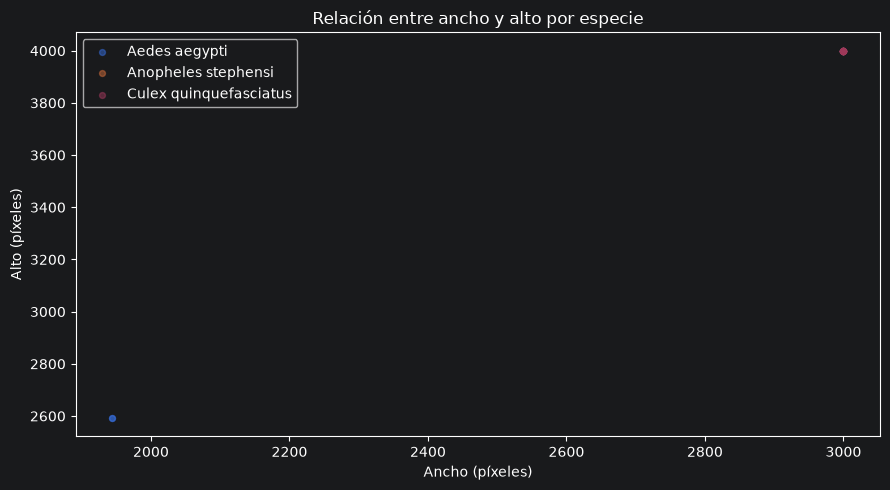

In [35]:
display(df_validas.groupby("Clase")[["Ancho", "Alto"]].describe().round(2))

plt.figure(figsize=(9, 5))
for clase, grupo in df_validas.groupby("Clase"):
    plt.scatter(grupo["Ancho"], grupo["Alto"], alpha=0.5, label=clase, s=18)
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.title("Relación entre ancho y alto por especie")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Resoluciones y proporciones de aspecto

Se identifican las resoluciones más frecuentes y la relación ancho/alto. Las fotografías cuadradas y rectangulares pueden requerir estrategias de preparación distintas para evitar deformaciones.

Cantidad de resoluciones distintas: 2


,Ancho,Alto,Cantidad
1,3000,4000,42
0,1944,2592,2


Resumen de relaciones de aspecto:


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,15.0,0.75,0.0,0.75,0.75,0.75,0.75,0.75
Anopheles stephensi,9.0,0.75,0.0,0.75,0.75,0.75,0.75,0.75
Culex quinquefasciatus,20.0,0.75,0.0,0.75,0.75,0.75,0.75,0.75


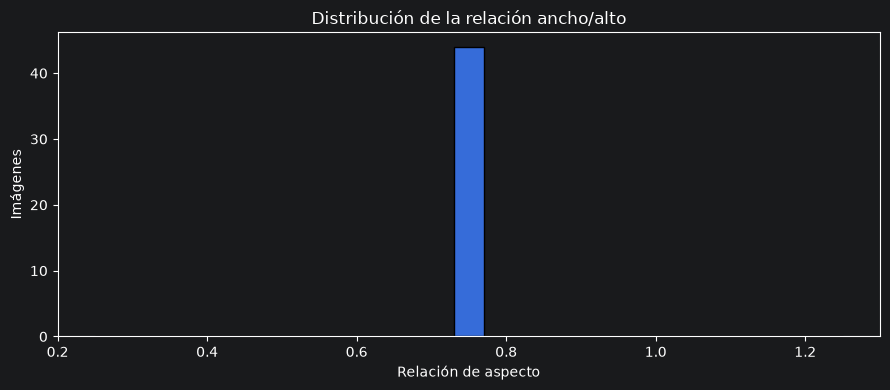

In [36]:
resoluciones = (
    df_validas.groupby(["Ancho", "Alto"])
    .size().reset_index(name="Cantidad")
    .sort_values("Cantidad", ascending=False)
)

df_validas["Relación de aspecto"] = df_validas["Ancho"] / df_validas["Alto"]
print("Cantidad de resoluciones distintas:", len(resoluciones))
display(resoluciones.head(15))
print("Resumen de relaciones de aspecto:")
display(df_validas.groupby("Clase")["Relación de aspecto"].describe().round(3))

plt.figure(figsize=(9, 4))
plt.hist(df_validas["Relación de aspecto"], bins=25, edgecolor="black")
plt.title("Distribución de la relación ancho/alto")
plt.xlabel("Relación de aspecto")
plt.ylabel("Imágenes")
plt.tight_layout()
plt.show()

## 10. Formatos de archivo

Se comparan las extensiones con el formato identificado por Pillow. Esto ayuda a detectar inconsistencias de formato que puedan causar fallos en los procesos de carga.

In [37]:
display(pd.crosstab(df_validas["Formato real"], df_validas["Clase"], margins=True))
print("Extensiones declaradas:")
display(df_validas["Extensión"].value_counts().rename_axis("Extensión").reset_index(name="Cantidad"))

formato_esperado = {
    ".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG", ".webp": "WEBP",
    ".bmp": "BMP", ".tif": "TIFF", ".tiff": "TIFF"
}
df_validas["Formato esperado"] = df_validas["Extensión"].map(formato_esperado)
inconsistencias_formato = df_validas[
    df_validas["Formato esperado"] != df_validas["Formato real"]
]
print("Archivos con extensión y formato diferentes:", len(inconsistencias_formato))
display(inconsistencias_formato[["Ruta", "Extensión", "Formato real"]].head(10))

Clase,Aedes aegypti,Anopheles stephensi,Culex quinquefasciatus,All
Formato real,,,,
JPEG,15,9,20,44
All,15,9,20,44


Extensiones declaradas:


,Extensión,Cantidad
0,.jpg,44


Archivos con extensión y formato diferentes: 0


,Ruta,Extensión,Formato real


## 11. Modos y canales de color

Se comprueba la cantidad de imágenes RGB, RGBA, escala de grises u otros modos. La CNN debe recibir entradas con una estructura de canales consistente.

Clase,Aedes aegypti,Anopheles stephensi,Culex quinquefasciatus,All
Modo de color,,,,
RGB,15,9,20,44
All,15,9,20,44


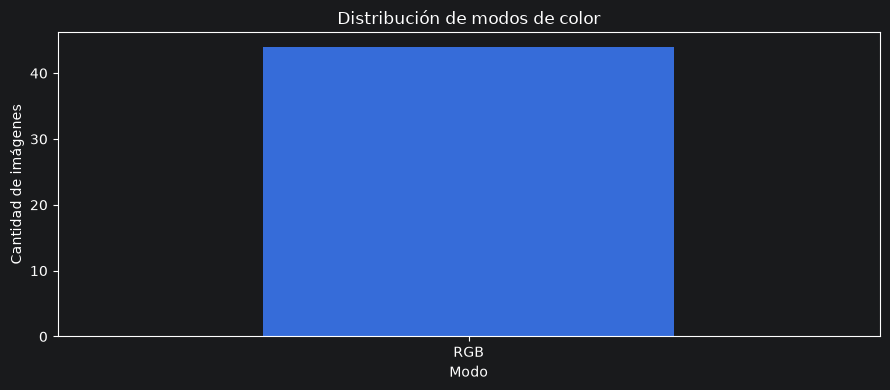

In [38]:
display(pd.crosstab(df_validas["Modo de color"], df_validas["Clase"], margins=True))

plt.figure(figsize=(9, 4))
df_validas["Modo de color"].value_counts().plot(kind="bar")
plt.title("Distribución de modos de color")
plt.xlabel("Modo")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Tamaño de los archivos

Se analizan los pesos de las imágenes para detectar archivos excepcionalmente pequeños o grandes. Un tamaño de archivo extremo no implica necesariamente mala calidad.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,15.0,2226.81,141.17,2029.00,2114.74,2231.17,2279.83,2597.30
Anopheles stephensi,9.0,2386.46,518.84,2036.60,2164.47,2247.65,2285.74,3745.37
Culex quinquefasciatus,20.0,3230.61,68.56,3100.97,3179.37,3229.26,3274.65,3361.33


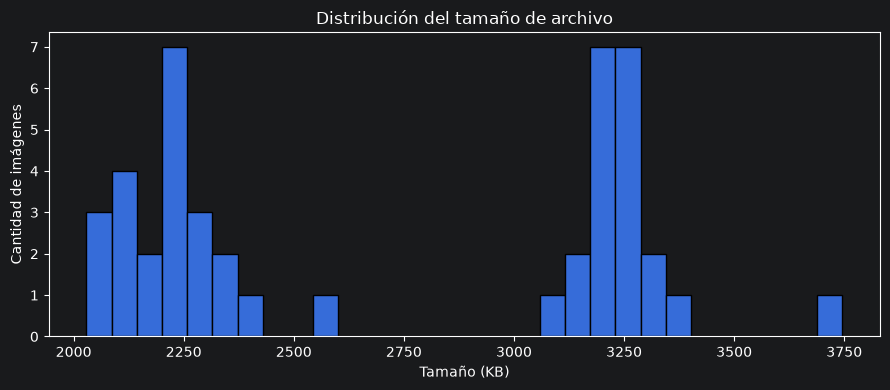

In [39]:
display(df_validas.groupby("Clase")["Tamaño (KB)"].describe().round(2))

plt.figure(figsize=(9, 4))
plt.hist(df_validas["Tamaño (KB)"], bins=30, edgecolor="black")
plt.title("Distribución del tamaño de archivo")
plt.xlabel("Tamaño (KB)")
plt.ylabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

## 13. Medición de brillo y contraste

Se calcula el brillo medio y la desviación estándar de intensidad de cada imagen. Para que la comparación sea consistente, las fotografías se convierten temporalmente a escala de grises y se reducen a 128 × 128 píxeles **solo en memoria**.

In [40]:
metricas_luz = []

for registro in df_validas.itertuples(index=False):
    with Image.open(registro.Ruta) as img:
        gris = ImageOps.exif_transpose(img).convert("L").resize((128, 128))
        pixels = np.asarray(gris, dtype=np.float32)
    metricas_luz.append({
        "Ruta": registro.Ruta,
        "Brillo": float(pixels.mean()),
        "Contraste": float(pixels.std()),
    })

df_luz = df_validas.merge(pd.DataFrame(metricas_luz), on="Ruta", how="left")
display(df_luz.groupby("Clase")[["Brillo", "Contraste"]].describe().round(2))

Brillo                                                 \
                        count    mean    std     min     25%     50%     75%   
Clase                                                                          
Aedes aegypti            15.0  198.13  17.62  152.71  204.07  205.08  206.52   
Anopheles stephensi       9.0  203.78   4.51  192.72  203.64  204.21  207.19   
Culex quinquefasciatus   20.0  194.82   1.53  189.68  194.37  195.14  195.63   

                               Contraste                                     \
                           max     count   mean    std    min    25%    50%   
Clase                                                                         
Aedes aegypti           208.96      15.0  16.58  11.44  10.52  12.18  12.70   
Anopheles stephensi     207.60       9.0  13.40   2.45   9.97  12.04  13.47   
Culex quinquefasciatus  196.79      20.0  13.31   1.14  10.73  12.72  13.66   

                                      
                          75%    max  
Clase                                 
Aedes aegypti           13.29  50.24  
Anopheles stephensi     14.24  18.47  
Culex quinquefasciatus  14.07  14.77

## 14. Distribución de brillo por clase

Se comparan los niveles de iluminación entre especies. Los valores bajos indican imágenes oscuras y los valores altos indican imágenes claras; no existe un umbral universal que determine calidad adecuada.

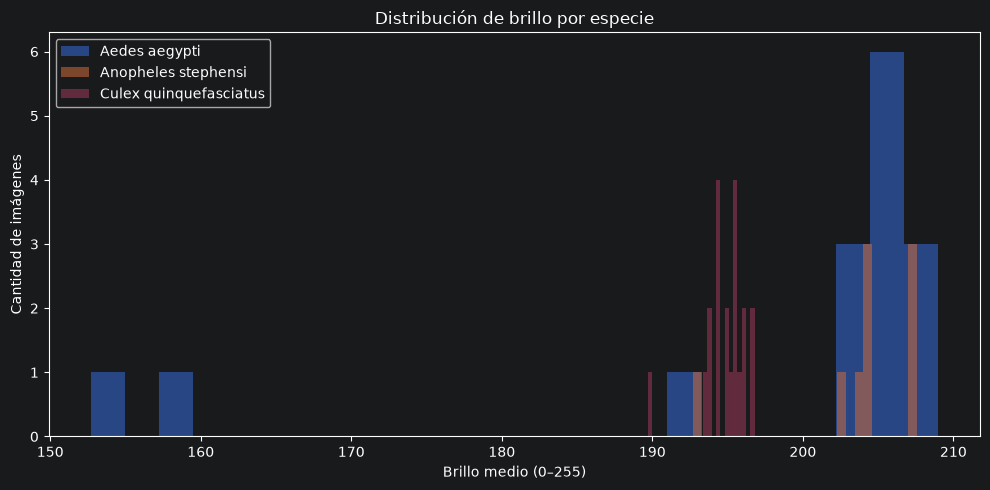

Diez imágenes con menor brillo:


,Clase,Ruta,Brillo
6,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,152.705139
5,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,159.195312
43,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,189.681030
0,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,191.222778
15,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,192.720520
29,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,193.472412
35,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,193.665100
24,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,193.816162
30,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,194.279297
42,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,194.393677


Diez imágenes con mayor brillo:


,Clase,Ruta,Brillo
12,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,208.955750
20,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,207.599182
23,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,207.342224
21,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,207.188171
14,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,207.132874
13,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,206.852356
4,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,206.528870
11,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,206.505981
1,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,205.363586
2,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,205.247437


In [41]:
plt.figure(figsize=(10, 5))
for clase, grupo in df_luz.groupby("Clase"):
    plt.hist(grupo["Brillo"], bins=25, alpha=0.55, label=clase)
plt.title("Distribución de brillo por especie")
plt.xlabel("Brillo medio (0–255)")
plt.ylabel("Cantidad de imágenes")
plt.legend()
plt.tight_layout()
plt.show()

print("Diez imágenes con menor brillo:")
display(df_luz.nsmallest(10, "Brillo")[["Clase", "Ruta", "Brillo"]])
print("Diez imágenes con mayor brillo:")
display(df_luz.nlargest(10, "Brillo")[["Clase", "Ruta", "Brillo"]])

## 15. Distribución de contraste por clase

Se mide cuánto varía la intensidad de los píxeles dentro de cada imagen. Las fotografías con bajo contraste pueden dificultar la distinción entre el mosquito y el fondo.

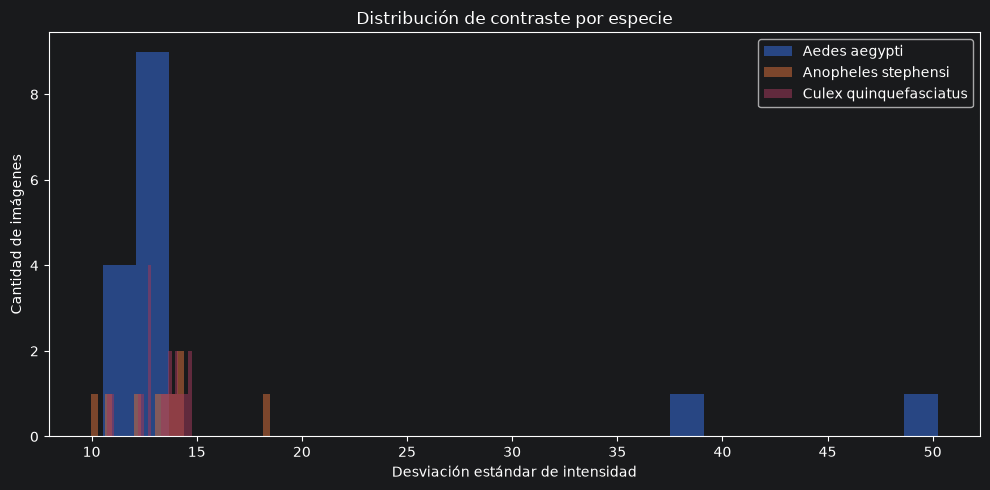

Imágenes con menor contraste:


,Clase,Ruta,Contraste
15,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,9.970046
10,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.521751
9,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.725432
33,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.732504
0,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.783879
18,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.827937
32,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,10.923152
23,Anopheles stephensi,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,12.036895
1,Aedes aegypti,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,12.076783
34,Culex quinquefasciatus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,12.230925


In [42]:
plt.figure(figsize=(10, 5))
for clase, grupo in df_luz.groupby("Clase"):
    plt.hist(grupo["Contraste"], bins=25, alpha=0.55, label=clase)
plt.title("Distribución de contraste por especie")
plt.xlabel("Desviación estándar de intensidad")
plt.ylabel("Cantidad de imágenes")
plt.legend()
plt.tight_layout()
plt.show()

print("Imágenes con menor contraste:")
display(df_luz.nsmallest(10, "Contraste")[["Clase", "Ruta", "Contraste"]])

## 16. Análisis de nitidez

Se calcula la varianza del Laplaciano en una versión gris de 128 × 128 píxeles. Los valores bajos pueden indicar desenfoque, pero también dependen del contenido, el ruido y el fondo; por ello deben revisarse visualmente antes de tomar decisiones.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,15.0,155.95,29.18,116.46,138.94,154.25,160.45,236.62
Anopheles stephensi,9.0,176.24,37.32,122.84,150.62,168.50,199.50,238.61
Culex quinquefasciatus,20.0,250.12,42.07,179.94,220.34,244.81,288.06,321.00


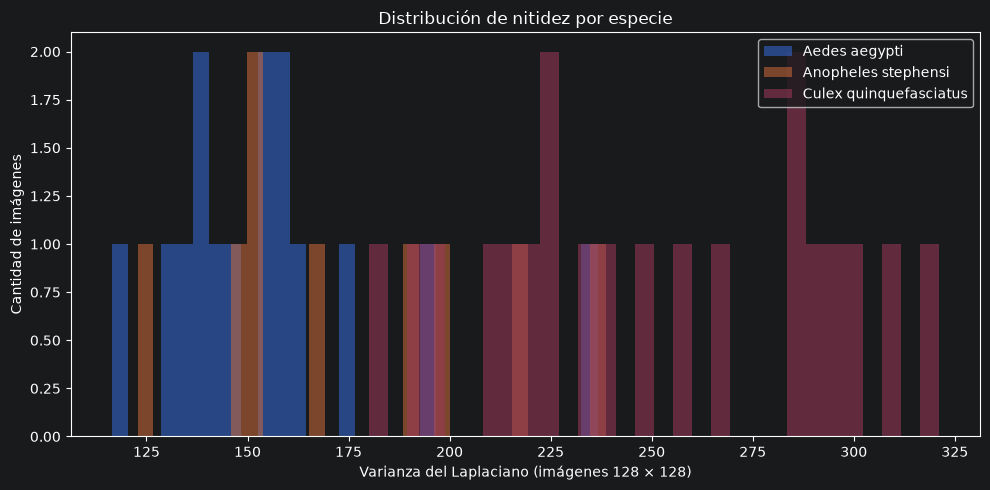

In [43]:
import cv2

registros_nitidez = []
for registro in df_validas.itertuples(index=False):
    with Image.open(registro.Ruta) as img:
        gris = ImageOps.exif_transpose(img).convert("L").resize((128, 128))
        pixels = np.asarray(gris, dtype=np.uint8)
    valor = cv2.Laplacian(pixels, cv2.CV_64F).var()
    registros_nitidez.append({"Ruta": registro.Ruta, "Nitidez": float(valor)})

df_nitidez = df_validas.merge(pd.DataFrame(registros_nitidez), on="Ruta", how="left")
display(df_nitidez.groupby("Clase")["Nitidez"].describe().round(2))

plt.figure(figsize=(10, 5))
for clase, grupo in df_nitidez.groupby("Clase"):
    plt.hist(grupo["Nitidez"], bins=30, alpha=0.55, label=clase)
plt.title("Distribución de nitidez por especie")
plt.xlabel("Varianza del Laplaciano (imágenes 128 × 128)")
plt.ylabel("Cantidad de imágenes")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Revisión visual de imágenes con nitidez baja

Se muestran las fotografías con menores valores de nitidez para comprobar si realmente presentan desenfoque. **No se eliminan archivos automáticamente.**

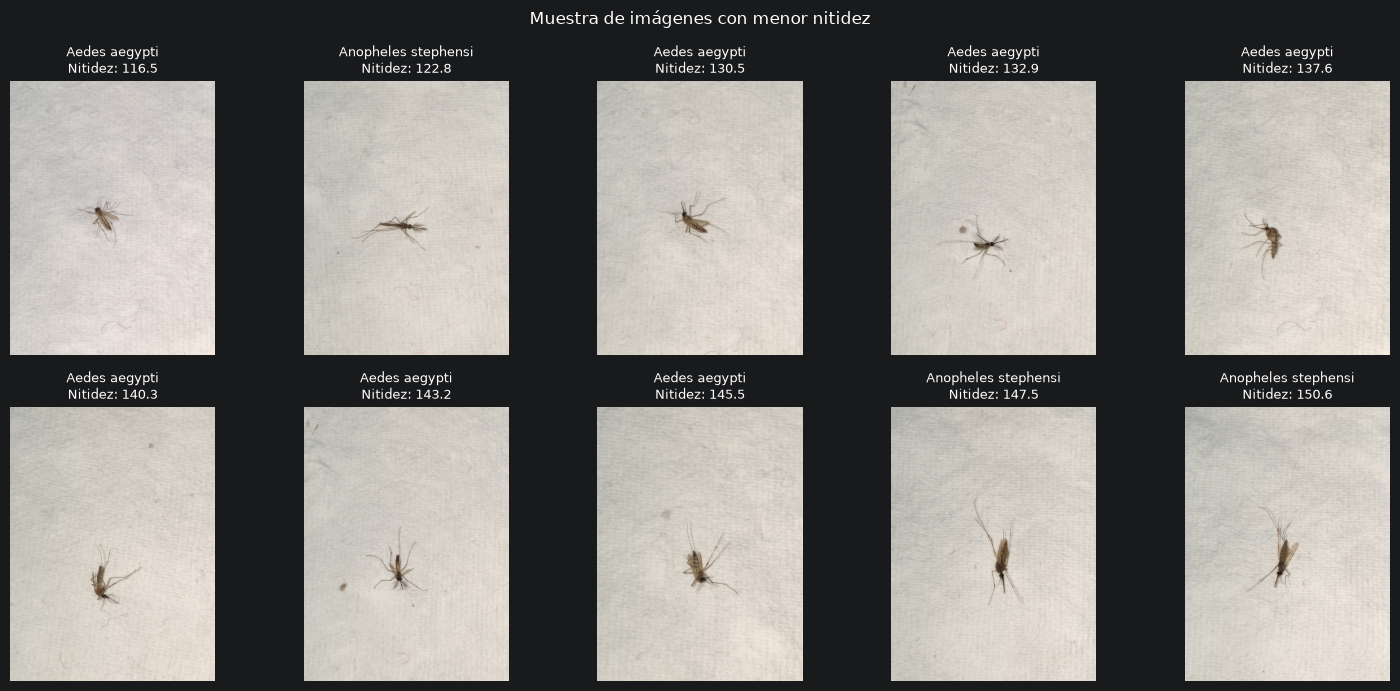

In [44]:
seleccion = df_nitidez.nsmallest(min(10, len(df_nitidez)), "Nitidez")
fig, ejes = plt.subplots(2, 5, figsize=(15, 7), squeeze=False)

for eje, (_, registro) in zip(ejes.flat, seleccion.iterrows()):
    with Image.open(registro["Ruta"]) as img:
        eje.imshow(ImageOps.exif_transpose(img).convert("RGB"))
    eje.set_title(f"{registro['Clase']}\nNitidez: {registro['Nitidez']:.1f}", fontsize=9)
    eje.axis("off")

for eje in list(ejes.flat)[len(seleccion):]:
    eje.axis("off")

plt.suptitle("Muestra de imágenes con menor nitidez")
plt.tight_layout()
plt.show()

## 18. Detección de archivos exactamente duplicados (SHA-256)

Se buscan archivos con contenido binario idéntico. Los duplicados podrían generar fuga de información si llegan tanto al conjunto de entrenamiento como al de prueba. La identificación no implica eliminación automática.

In [45]:
def calcular_sha256(ruta_archivo):
    digest = hashlib.sha256()
    with open(ruta_archivo, "rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(bloque)
    return digest.hexdigest()


df_hash = df_validas[["Ruta", "Clase"]].copy()
df_hash["SHA256"] = df_hash["Ruta"].apply(calcular_sha256)

grupos_repetidos = df_hash[df_hash.duplicated("SHA256", keep=False)].sort_values("SHA256")
repeticiones = int(df_hash.duplicated("SHA256", keep="first").sum())

print("Imágenes analizadas:", len(df_hash))
print("Archivos duplicados adicionales:", repeticiones)
print("Archivos únicos (SHA-256):", df_hash["SHA256"].nunique())
print("Grupos de archivos repetidos:", grupos_repetidos["SHA256"].nunique())
display(grupos_repetidos[["Clase", "Ruta", "SHA256"]].head(20))

# Comprobar si un mismo archivo aparece etiquetado en más de una clase
conflictos = (
    df_hash.groupby("SHA256")["Clase"].nunique()
    .loc[lambda s: s > 1]
)
print("Grupos duplicados con etiquetas distintas:", len(conflictos))

Imágenes analizadas: 44
Archivos duplicados adicionales: 0
Archivos únicos (SHA-256): 44
Grupos de archivos repetidos: 0


,Clase,Ruta,SHA256


Grupos duplicados con etiquetas distintas: 0


## 19. Posibles imágenes visualmente repetidas (dHash)

Se utiliza un hash perceptual sencillo para señalar **candidatos** a imágenes visualmente idénticas o muy similares, incluso si los bytes son diferentes. Que coincidan los hashes no prueba que sean la misma fotografía; requiere revisión manual.

In [46]:
def dhash_imagen(ruta_archivo):
    with Image.open(ruta_archivo) as img:
        gris = ImageOps.exif_transpose(img).convert("L").resize((9, 8))
        matriz = np.asarray(gris, dtype=np.int16)
    bits = matriz[:, 1:] > matriz[:, :-1]
    return "".join("1" if valor else "0" for valor in bits.ravel())


df_similares = df_hash.copy()
df_similares["dHash"] = df_similares["Ruta"].apply(dhash_imagen)

# Excluir primero las coincidencias byte a byte, ya contabilizadas antes.
df_una_por_sha = df_similares.drop_duplicates("SHA256").copy()
candidatas_visuales = df_una_por_sha[
    df_una_por_sha.duplicated("dHash", keep=False)
].sort_values("dHash")

print("Candidatas visuales (archivos binariamente distintos):", len(candidatas_visuales))
print("Grupos de dHash repetido:", candidatas_visuales["dHash"].nunique())
display(candidatas_visuales[["Clase", "Ruta", "dHash"]].head(20))

Candidatas visuales (archivos binariamente distintos): 0
Grupos de dHash repetido: 0


,Clase,Ruta,dHash


## 20. Evaluación final del desbalance de clases

Se calcula la relación entre la clase con más imágenes y la clase con menos imágenes, considerando **solo las especies identificadas**. No se realiza balanceo en este notebook.

In [47]:
conteo_identificadas = tabla_conteo[
    tabla_conteo["Clase"] != "Sin identificar"
].copy()

if len(conteo_identificadas) >= 2:
    mayor = int(conteo_identificadas["Cantidad de imágenes"].max())
    menor = int(conteo_identificadas["Cantidad de imágenes"].min())
    print(f"Relación mayoritaria/minoritaria: {mayor / menor:.2f}:1")
    print(f"Diferencia de imágenes: {mayor - menor}")
else:
    print("No hay suficientes clases identificadas para calcular la relación de desbalance.")

display(conteo_identificadas)

Relación mayoritaria/minoritaria: 2.22:1
Diferencia de imágenes: 11


,Clase,Cantidad de imágenes,Porcentaje (%)
0,Culex quinquefasciatus,20,45.45
1,Aedes aegypti,15,34.09
2,Anopheles stephensi,9,20.45


## 21. Resumen automático del EDA

Se reúnen las principales métricas obtenidas. Esta tabla permite redactar posteriormente una conclusión sustentada en los resultados reales del dataset.

In [48]:
resumen = pd.DataFrame([
    ("Total de imágenes encontradas", len(inventario)),
    ("Clases identificadas", inventario.loc[inventario["Clase"] != "Sin identificar", "Clase"].nunique()),
    ("Imágenes sin clase identificada", int((inventario["Clase"] == "Sin identificar").sum())),
    ("Imágenes válidas", len(df_validas)),
    ("Imágenes dañadas", len(df_danadas)),
    ("Resoluciones diferentes", len(resoluciones)),
    ("Modos de color diferentes", df_validas["Modo de color"].nunique()),
    ("Formatos reales diferentes", df_validas["Formato real"].nunique()),
    ("Archivos con formato inconsistente", len(inconsistencias_formato)),
    ("Duplicados exactos adicionales", repeticiones),
    ("Grupos de duplicados con etiquetas distintas", len(conflictos)),
    ("Candidatos a imágenes visualmente repetidas", len(candidatas_visuales)),
    ("Brillo medio del dataset", round(df_luz["Brillo"].mean(), 2)),
    ("Contraste medio del dataset", round(df_luz["Contraste"].mean(), 2)),
    ("Nitidez mediana", round(df_nitidez["Nitidez"].median(), 2)),
], columns=["Indicador", "Resultado"])

display(resumen)

,Indicador,Resultado
0,Total de imágenes encontradas,44.00
1,Clases identificadas,3.00
2,Imágenes sin clase identificada,0.00
3,Imágenes válidas,44.00
4,Imágenes dañadas,0.00
5,Resoluciones diferentes,2.00
6,Modos de color diferentes,1.00
7,Formatos reales diferentes,1.00
8,Archivos con formato inconsistente,0.00
9,Duplicados exactos adicionales,0.00



## 22. Conclusiones generales del EDA

El análisis exploratorio del dataset Mendeley permitió identificar las características principales de las imágenes de tres especies de mosquitos, evaluando su distribución, dimensiones, calidad visual e integridad.

### 22.1. Principales hallazgos

1. **Cantidad de imágenes:** se analizaron 44 imágenes originales distribuidas entre tres especies: Aedes aegypti, Anopheles stephensi y Culex quinquefasciatus.

2. **Distribución de clases:** el conjunto contiene 15 imágenes de Aedes aegypti, 9 de Anopheles stephensi y 20 de Culex quinquefasciatus. Existe un desbalance entre las especies y una cantidad limitada de muestras.

3. **Dimensiones:** se identificaron dos resoluciones diferentes, por lo que será necesario unificar el tamaño de las imágenes antes del entrenamiento.

4. **Formatos y colores:** se identificó un único formato de archivo y un único modo de color, lo que favorece la uniformidad del procesamiento.

5. **Brillo:** el brillo promedio fue de 197,78 sobre una escala de 0 a 255. Las imágenes presentan una iluminación relativamente alta, aunque existen diferencias entre especies.

6. **Contraste:** se obtuvo un contraste promedio de 14,44. La mayoría de las imágenes presenta valores similares, aunque algunas fotografías de Aedes aegypti muestran valores considerablemente superiores.

7. **Nitidez:** se obtuvo una mediana de 194,37 mediante la varianza del Laplaciano. Se observaron diferencias entre imágenes, por lo que conviene revisar las fotografías con valores extremos.

8. **Integridad:** las 44 imágenes se procesaron correctamente y no se encontraron archivos dañados.

9. **Duplicados:** no se identificaron archivos exactamente duplicados ni candidatos a duplicados visuales mediante los métodos utilizados.

### 22.2. Recomendaciones para el entrenamiento

- Redimensionar las imágenes según los requisitos de la arquitectura CNN.
- Aplicar técnicas de aumento de datos para incrementar la variedad de imágenes disponibles durante el entrenamiento.
- Considerar el desbalance de clases al preparar los datos.
- Revisar las imágenes con niveles extremos de brillo, contraste y nitidez.
- Evitar que versiones aumentadas de una misma imagen original aparezcan en entrenamiento y prueba.
- Complementar este dataset con las demás fuentes de imágenes del proyecto.
- Utilizar las etiquetas de especies de forma consistente al combinar los diferentes datasets.

### 22.3. Conclusión final

El dataset Mendeley presenta una estructura organizada y una adecuada integridad de archivos, sin imágenes dañadas ni duplicados detectados.

Sin embargo, su principal limitación es la cantidad reducida de imágenes originales, lo que podría dificultar el entrenamiento de una CNN capaz de generalizar correctamente.

También se identificaron diferencias de resolución, iluminación, contraste y nitidez que deberán considerarse durante el preprocesamiento.

Por estas razones, se recomienda utilizar este dataset como complemento de las demás fuentes de imágenes de VectorIA, en lugar de emplearlo como única fuente de entrenamiento.

Finalmente, el conjunto incluye Anopheles stephensi, una especie que no forma parte de las tres clases finales propuestas para VectorIA. Por lo tanto, será necesario definir cómo utilizar o excluir esa clase durante la integración de los datasets.
